Python : 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
PyTorch : 2.15.0+cpu
CUDA disponible : False


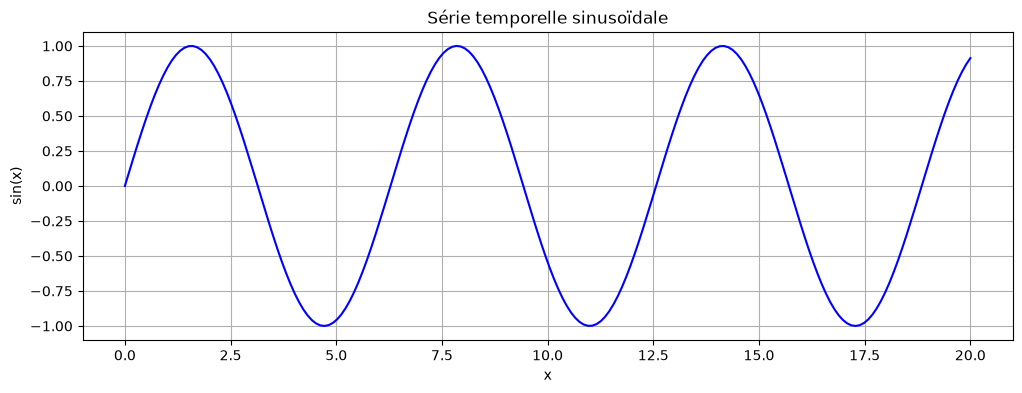

In [1]:
%matplotlib inline

import sys
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

plt.figure(figsize=(12, 4))
plt.plot(periode.numpy(), serie.numpy(), color="blue")
plt.title("Série temporelle sinusoïdale")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

## 2. Implémentation d'un RNN

Le RNN (Recurrent Neural Network) est un réseau de neurones
récurrent conçu pour traiter des données séquentielles.

Il traite les éléments d'une séquence successivement en
conservant un état caché qui contient les informations
des étapes précédentes.

Dans cette partie, nous utilisons un RNN pour prédire la
prochaine valeur de la série temporelle sinusoïdale à partir
des 10 valeurs précédentes.

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Génération de la série temporelle
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

longueur_sequence = 10

# Création des séquences
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Séparation des données
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : torch.Size([150, 10, 1])
y_train : torch.Size([150, 1])
X_test  : torch.Size([40, 10, 1])
y_test  : torch.Size([40, 1])


In [6]:
class SimpleRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=16,
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]

        return self.sortie(dernier_etat)


modele_rnn = SimpleRNN()

print(modele_rnn)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [7]:
critere = nn.MSELoss()

optimiseur_rnn = torch.optim.Adam(
    modele_rnn.parameters(),
    lr=0.01
)

epochs = 300
historique_rnn = []

In [8]:
modele_rnn.train()

for epoch in range(epochs):

    predictions = modele_rnn(X_train)

    perte = critere(predictions, y_train)

    optimiseur_rnn.zero_grad()

    perte.backward()

    optimiseur_rnn.step()

    historique_rnn.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025


In [9]:
modele_rnn.eval()

with torch.no_grad():

    predictions_rnn = modele_rnn(X_test)

    erreur_test_rnn = critere(
        predictions_rnn,
        y_test
    )

print(f"Erreur de test : {erreur_test_rnn.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_rnn[0].item():.4f}")

Erreur de test : 0.000028
Valeur réelle : -0.3639
Valeur prédite : -0.3601


### 2.4. Visualisation des résultats

Nous représentons l'évolution de la fonction de perte
pendant l'entraînement ainsi que la comparaison entre
les valeurs réelles et les prédictions du RNN.

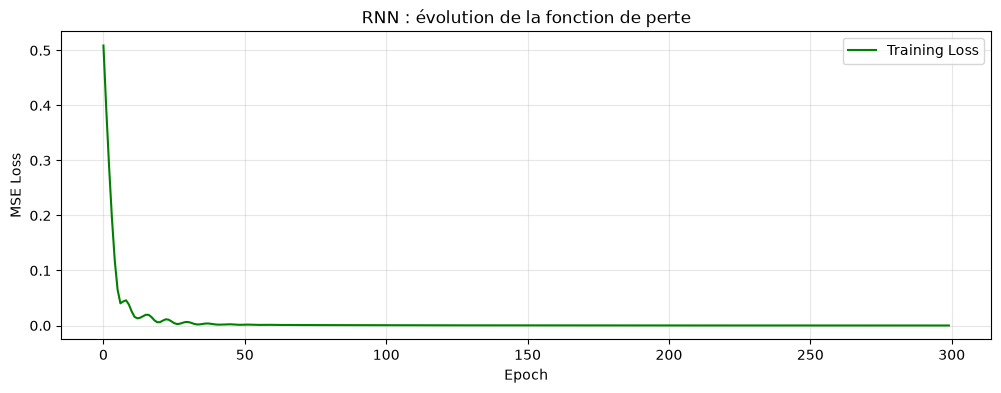

In [10]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_rnn,
    color="green",
    label="Training Loss"
)

plt.title("RNN : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

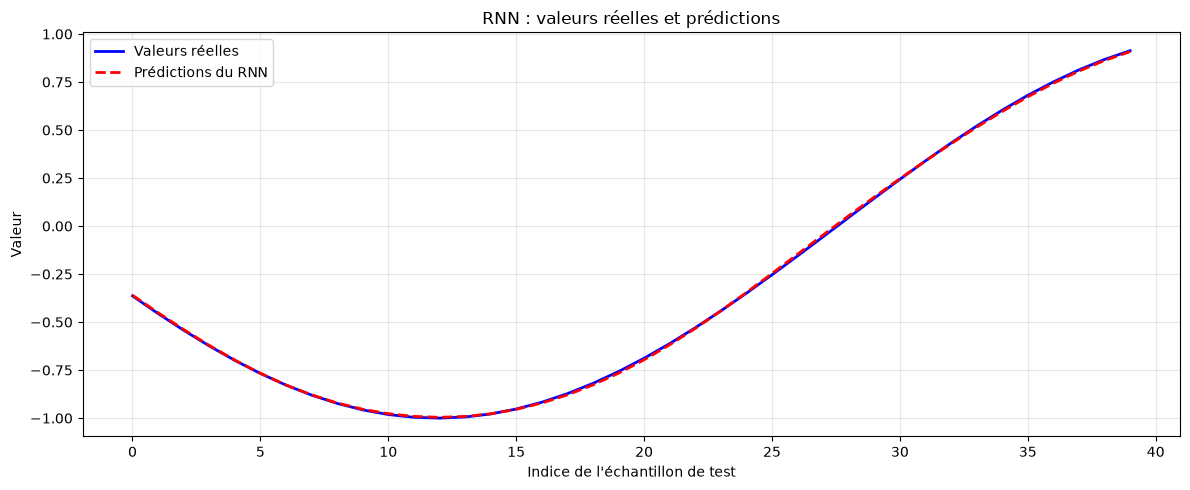

In [11]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_rnn = (
    predictions_rnn.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_rnn,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5. Interprétation des résultats

Les résultats montrent que le RNN est capable d'apprendre
les dépendances temporelles de la série sinusoïdale.

La diminution de la fonction de perte indique que le modèle
améliore progressivement ses prédictions pendant l'entraînement.

Les valeurs prédites sont proches des valeurs réelles,
ce qui traduit une bonne capacité de généralisation sur
cette série temporelle simple.

Cependant, les RNN présentent certaines limites :

- Le traitement séquentiel des données.
- La difficulté de capturer les dépendances à long terme.
- Le problème de disparition du gradient (Vanishing Gradient).

Ces limitations motivent l'utilisation des architectures
LSTM et Transformer.

## 3. Implémentation du LSTM

Le LSTM (Long Short-Term Memory) est une architecture
de réseau de neurones récurrent conçue pour améliorer
la mémorisation des dépendances à long terme.

Contrairement au RNN classique, le LSTM dispose d'un
état de cellule et de trois portes principales :

- Forget Gate : sélectionne les informations à oublier.
- Input Gate : sélectionne les informations à mémoriser.
- Output Gate : contrôle les informations transmises en sortie.

Cette architecture permet de réduire le problème de
disparition du gradient rencontré dans les RNN classiques.

Nous utilisons le même jeu de données que celui du RNN
afin de comparer les performances des deux architectures.

In [12]:
class SimpleLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=16,
            num_layers=1,
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):

        etats, (h_final, c_final) = self.lstm(x)

        dernier_etat = etats[:, -1, :]

        return self.sortie(dernier_etat)


modele_lstm = SimpleLSTM()

print(modele_lstm)

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [13]:
critere = nn.MSELoss()

optimiseur_lstm = torch.optim.Adam(
    modele_lstm.parameters(),
    lr=0.01
)

epochs = 300
historique_lstm = []

In [14]:
modele_lstm.train()

for epoch in range(epochs):

    predictions = modele_lstm(X_train)

    perte = critere(predictions, y_train)

    optimiseur_lstm.zero_grad()

    perte.backward()

    optimiseur_lstm.step()

    historique_lstm.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.002550
Epoch 100 | Erreur : 0.000239
Epoch 150 | Erreur : 0.000019
Epoch 200 | Erreur : 0.000014
Epoch 250 | Erreur : 0.000012
Epoch 300 | Erreur : 0.000010


In [15]:
modele_lstm.eval()

with torch.no_grad():

    predictions_lstm = modele_lstm(X_test)

    erreur_test_lstm = critere(
        predictions_lstm,
        y_test
    )

print(f"Erreur de test : {erreur_test_lstm.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_lstm[0].item():.4f}")

Erreur de test : 0.000010
Valeur réelle : -0.3639
Valeur prédite : -0.3619


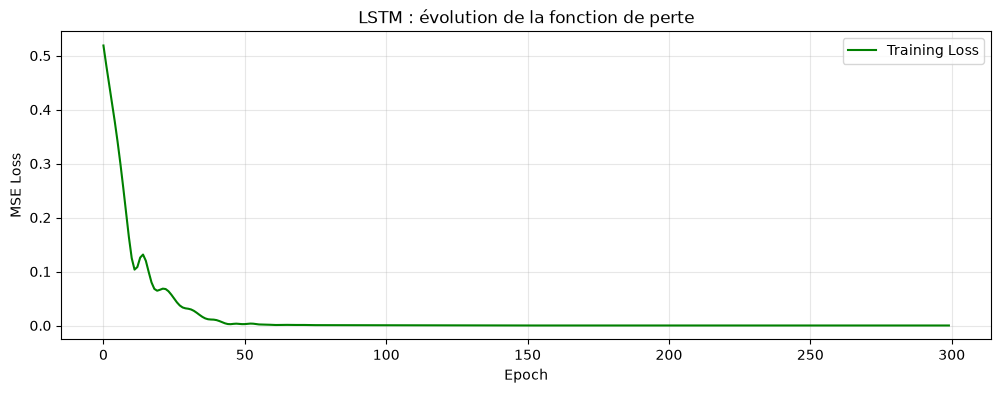

In [16]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_lstm,
    color="green",
    label="Training Loss"
)

plt.title("LSTM : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

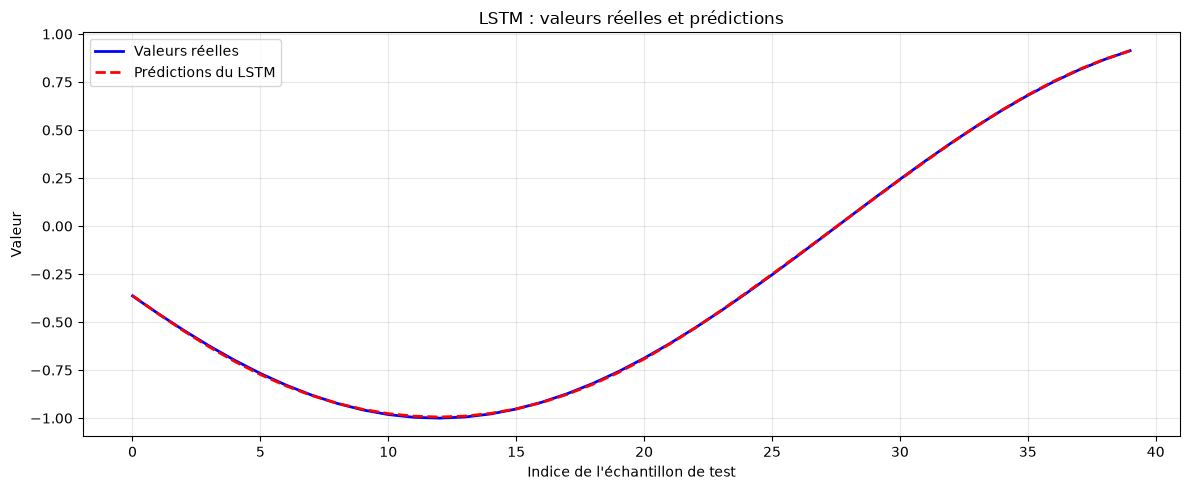

In [17]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_lstm = (
    predictions_lstm.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_lstm,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5. Interprétation des résultats

Le modèle LSTM est capable d'apprendre les dépendances
temporelles de la série sinusoïdale.

La diminution progressive de la fonction de perte montre
que le modèle améliore ses prédictions durant l'entraînement.

Les valeurs prédites sont très proches des valeurs réelles.

Grâce à son mécanisme de portes et à son état de cellule,
le LSTM est conçu pour mieux conserver les informations
à long terme qu'un RNN classique.

Cependant, comme le RNN, le LSTM conserve un traitement
séquentiel des données, ce qui limite la parallélisation
des calculs.

Pour dépasser cette limitation, nous étudierons ensuite
l'architecture Transformer, basée sur le mécanisme d'attention.

In [18]:
import pandas as pd

comparaison = pd.DataFrame({
    "Modèle": ["RNN", "LSTM"],
    "MSE Test": [
        erreur_test_rnn.item(),
        erreur_test_lstm.item()
    ],
    "RMSE Test": [
        np.sqrt(erreur_test_rnn.item()),
        np.sqrt(erreur_test_lstm.item())
    ],
    "Nombre de paramètres": [
        sum(p.numel() for p in modele_rnn.parameters()),
        sum(p.numel() for p in modele_lstm.parameters())
    ]
})

comparaison

,Modèle,MSE Test,RMSE Test,Nombre de paramètres
0,RNN,0.000028,0.005256,321
1,LSTM,0.000010,0.003150,1233


## 4. Implémentation du Transformer

Le Transformer est une architecture de Deep Learning
introduite en 2017 dans l'article "Attention Is All You Need".

Contrairement aux RNN et LSTM, il repose principalement
sur le mécanisme d'attention, qui permet de traiter les
éléments d'une séquence en parallèle.

Les principaux composants du Transformer sont :

- Projection linéaire des entrées.
- Encodage positionnel.
- Multi-Head Self-Attention.
- Connexions résiduelles.
- Layer Normalization.
- Feed Forward Network.

Dans cette partie, nous utilisons un Transformer Encoder
pour prédire la prochaine valeur de la série sinusoïdale.

In [19]:
class MiniTransformer(nn.Module):

    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        self.projection = nn.Linear(1, dimension)

        self.positions = nn.Embedding(
            longueur_max,
            dimension
        )

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):

        longueur = x.size(1)

        x = self.projection(x)

        indices = torch.arange(
            longueur,
            device=x.device
        )

        positions = self.positions(indices)

        x = x + positions.unsqueeze(0)

        representations = self.encodeur(x)

        derniere_position = representations[:, -1, :]

        return self.sortie(derniere_position)


modele_transformer = MiniTransformer(
    longueur_max=longueur_sequence
)

print(modele_transformer)

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [21]:
critere = nn.MSELoss()

optimiseur_transformer = torch.optim.Adam(
    modele_transformer.parameters(),
    lr=0.01
)

epochs = 300
historique_transformer = []

In [22]:
modele_transformer.train()

for epoch in range(epochs):

    predictions = modele_transformer(X_train)

    perte = critere(predictions, y_train)

    optimiseur_transformer.zero_grad()

    perte.backward()

    optimiseur_transformer.step()

    historique_transformer.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.000699
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.001928
Epoch 200 | Erreur : 0.000108
Epoch 250 | Erreur : 0.000060
Epoch 300 | Erreur : 0.000037


In [23]:
modele_transformer.eval()

with torch.no_grad():

    predictions_transformer = modele_transformer(X_test)

    erreur_test_transformer = critere(
        predictions_transformer,
        y_test
    )

print(f"Erreur de test : {erreur_test_transformer.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_transformer[0].item():.4f}")

Erreur de test : 0.000053
Valeur réelle : -0.3639
Valeur prédite : -0.3693


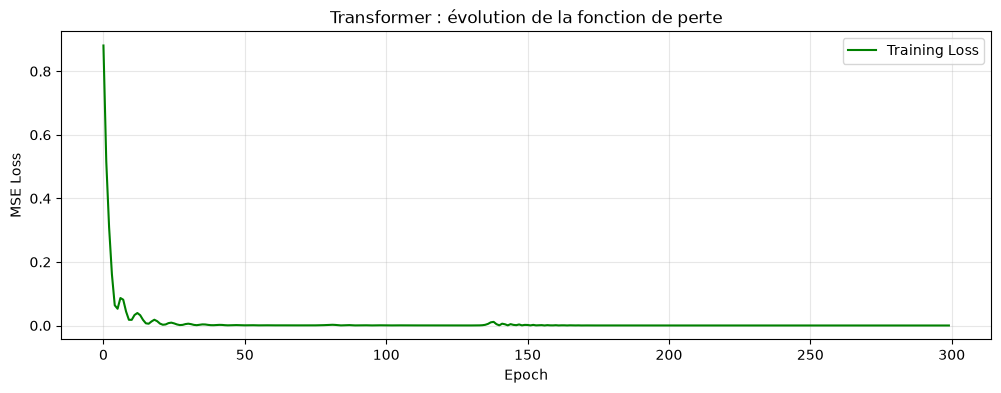

In [24]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_transformer,
    color="green",
    label="Training Loss"
)

plt.title("Transformer : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

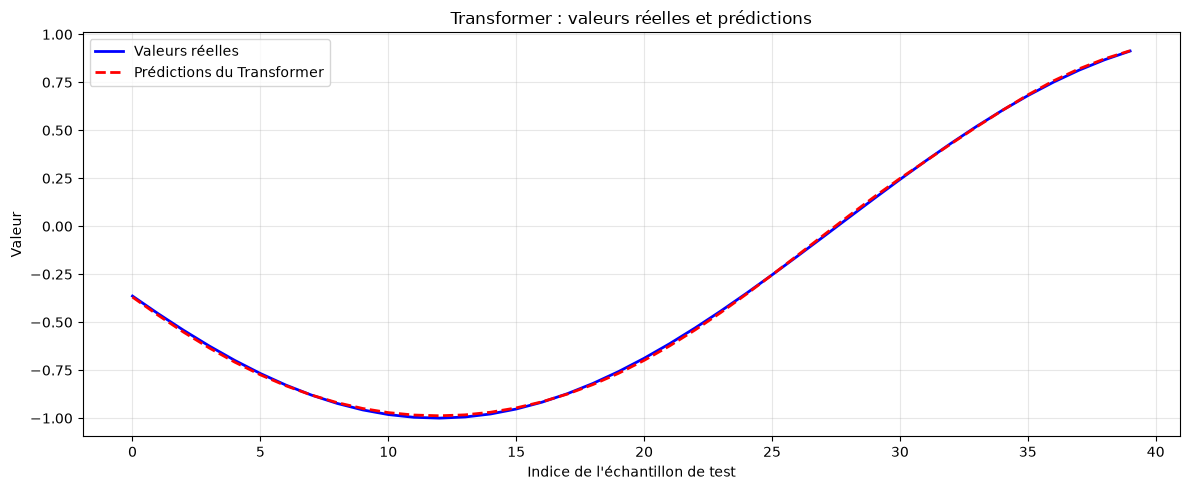

In [25]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_transformer = (
    predictions_transformer.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_transformer,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation des résultats

Les résultats montrent que le Transformer est capable
d'apprendre les dépendances temporelles de la série
sinusoïdale grâce au mécanisme de Self-Attention.

La diminution de la fonction de perte indique une
amélioration progressive des prédictions.

Contrairement aux RNN et LSTM, le Transformer ne repose
pas sur un traitement récurrent des données.

Ses principaux avantages sont :

- Le traitement parallèle des éléments de la séquence.
- La capture des relations entre les éléments éloignés.
- L'utilisation de plusieurs têtes d'attention.
- La prise en compte de l'ordre des éléments grâce
  aux embeddings positionnels.

Cependant, le mécanisme d'attention classique présente
un coût de calcul quadratique par rapport à la longueur
de la séquence.

## 5. Étude comparative : RNN, LSTM et Transformer

Dans cette section, nous comparons les trois architectures
en utilisant le même jeu de données et les mêmes paramètres
d'entraînement.

Les critères de comparaison sont :

- MSE : erreur quadratique moyenne.
- RMSE : racine de l'erreur quadratique moyenne.
- MAE : erreur absolue moyenne.
- Nombre de paramètres du modèle.

In [26]:
import pandas as pd

comparaison = pd.DataFrame({

    "Modèle": ["RNN", "LSTM", "Transformer"],

    "MSE Test": [
        erreur_test_rnn.item(),
        erreur_test_lstm.item(),
        erreur_test_transformer.item()
    ],

    "RMSE Test": [
        np.sqrt(erreur_test_rnn.item()),
        np.sqrt(erreur_test_lstm.item()),
        np.sqrt(erreur_test_transformer.item())
    ],

    "MAE Test": [
        torch.mean(torch.abs(predictions_rnn - y_test)).item(),
        torch.mean(torch.abs(predictions_lstm - y_test)).item(),
        torch.mean(torch.abs(predictions_transformer - y_test)).item()
    ],

    "Nombre de paramètres": [
        sum(p.numel() for p in modele_rnn.parameters()),
        sum(p.numel() for p in modele_lstm.parameters()),
        sum(p.numel() for p in modele_transformer.parameters())
    ]
})

comparaison.style.format({
    "MSE Test": "{:.8f}",
    "RMSE Test": "{:.6f}",
    "MAE Test": "{:.6f}"
})

,Modèle,MSE Test,RMSE Test,MAE Test,Nombre de paramètres
0,RNN,0.00002763,0.005256,0.004562,321
1,LSTM,0.00000992,0.003150,0.002636,1233
2,Transformer,0.00005281,0.007267,0.006346,2433


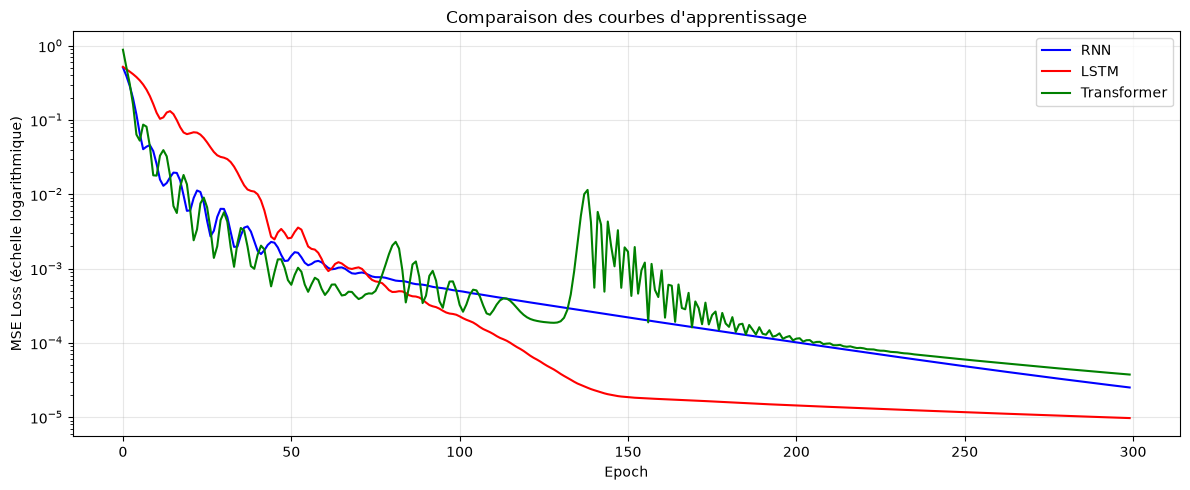

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(historique_rnn, label="RNN", color="blue")
plt.plot(historique_lstm, label="LSTM", color="red")
plt.plot(historique_transformer, label="Transformer", color="green")

plt.yscale("log")

plt.title("Comparaison des courbes d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (échelle logarithmique)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

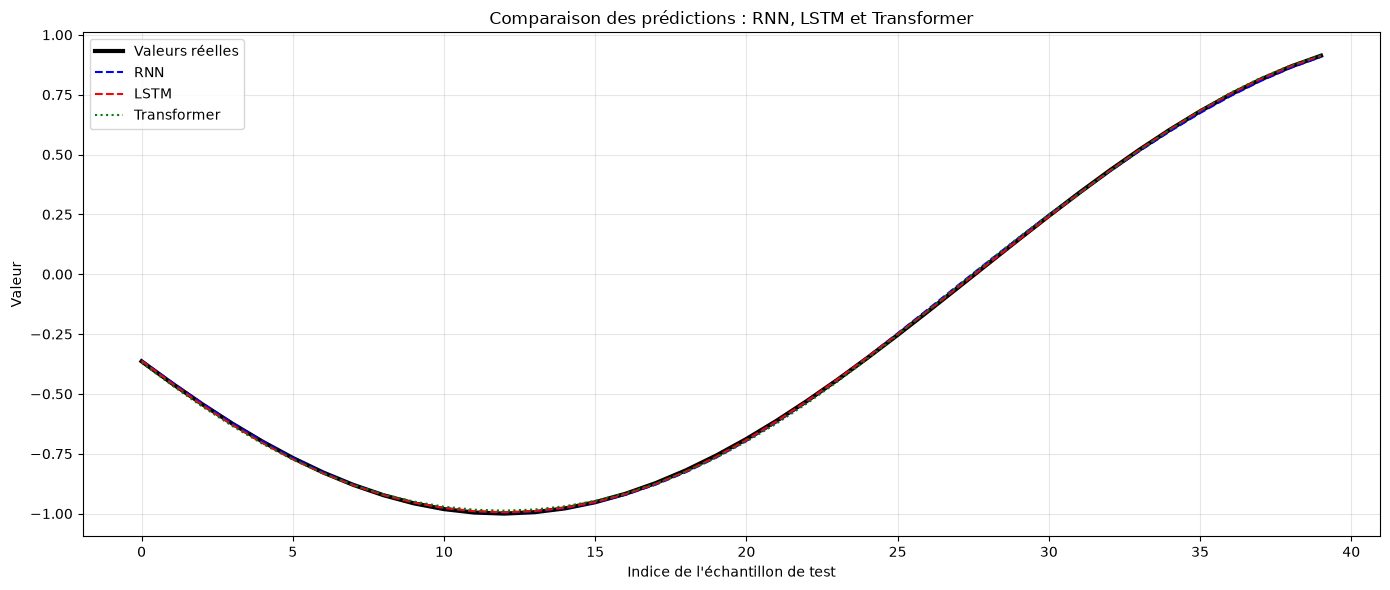

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="black",
    linewidth=3
)

plt.plot(
    valeurs_predites_rnn,
    label="RNN",
    color="blue",
    linestyle="--"
)

plt.plot(
    valeurs_predites_lstm,
    label="LSTM",
    color="red",
    linestyle="--"
)

plt.plot(
    valeurs_predites_transformer,
    label="Transformer",
    color="green",
    linestyle=":"
)

plt.title("Comparaison des prédictions : RNN, LSTM et Transformer")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparaison des architectures

| Critère | RNN | LSTM | Transformer |
|---|---|---|---|
| Mécanisme principal | Récurrence | Récurrence avec portes | Self-Attention |
| Traitement | Séquentiel | Séquentiel | Parallèle |
| Mémoire | État caché | État caché et état de cellule | Attention |
| Dépendances longues | Limitées | Améliorées | Directes |
| Information de position | Implicite | Implicite | Explicite dans notre modèle |
| Vanishing Gradient | Sensible | Atténué | Pas de chaîne récurrente temporelle |

Le choix de l'architecture dépend de la nature des données,
de la complexité du problème et des ressources disponibles.

Un Transformer n'est pas nécessairement plus performant
qu'un RNN ou un LSTM sur une série temporelle simple.

## 6. Implémentation basée sur GPT-2

GPT (Generative Pre-trained Transformer) est un modèle
de langage basé sur une architecture Transformer
de type Decoder-only.

Son objectif principal est de prédire le prochain token
à partir des tokens précédents.

GPT utilise un mécanisme d'attention causale qui empêche
le modèle d'accéder aux tokens futurs.

Dans cette partie, nous utilisons le modèle GPT-2
pré-entraîné pour générer automatiquement du texte
à partir d'une phrase initiale.

In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_modele = "gpt2"

tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele)

modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele)

tokenizer_gpt.pad_token = tokenizer_gpt.eos_token

modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id

modele_gpt.eval()

print("Modèle GPT-2 chargé avec succès !")
print("Taille du vocabulaire :", tokenizer_gpt.vocab_size)
print("Nombre de paramètres :", sum(
    p.numel() for p in modele_gpt.parameters()
))

C:\Users\HP\anaconda3\envs\transformer\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\HP\anaconda3\envs\transformer\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see

Modèle GPT-2 chargé avec succès !
Taille du vocabulaire : 50257
Nombre de paramètres : 124439808


In [2]:
texte_gpt = "Artificial intelligence can help people"

entrees_gpt = tokenizer_gpt(
    texte_gpt,
    return_tensors="pt"
)

print("Texte original :", texte_gpt)

print("\nTokens :")
print(tokenizer_gpt.tokenize(texte_gpt))

print("\nIdentifiants des tokens :")
print(entrees_gpt["input_ids"])

print("\nDimensions de l'entrée :")
print(entrees_gpt["input_ids"].shape)

Texte original : Artificial intelligence can help people

Tokens :
['Art', 'ificial', 'Ġintelligence', 'Ġcan', 'Ġhelp', 'Ġpeople']

Identifiants des tokens :
tensor([[8001, 9542, 4430,  460, 1037,  661]])

Dimensions de l'entrée :
torch.Size([1, 6])


In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_modele = "gpt2"

tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele)

modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele)

tokenizer_gpt.pad_token = tokenizer_gpt.eos_token

modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id

modele_gpt.eval()

print("Modèle GPT-2 chargé avec succès !")
print("Taille du vocabulaire :", tokenizer_gpt.vocab_size)
print("Nombre de paramètres :", sum(
    p.numel() for p in modele_gpt.parameters()
))

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 441.26it/s]

Modèle GPT-2 chargé avec succès !
Taille du vocabulaire : 50257
Nombre de paramètres : 124439808


In [5]:
torch.manual_seed(42)

with torch.no_grad():

    sortie_gpt = modele_gpt.generate(
        **entrees_gpt,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer_gpt.pad_token_id
    )

texte_genere = tokenizer_gpt.decode(
    sortie_gpt[0],
    skip_special_tokens=True
)

print("Texte initial :")
print(texte_gpt)

print("\nTexte généré :")
print(texte_genere)

Texte initial :
Artificial intelligence can help people

Texte généré :
Artificial intelligence can help people understand and understand a vast range of things, from our everyday lives to the everyday activities of others, and from our work. For this reason, we think it's important to understand what is and isn't possible.


In [6]:
temperatures = [0.2, 0.8, 1.5]

for temperature in temperatures:

    torch.manual_seed(42)

    with torch.no_grad():

        sortie = modele_gpt.generate(
            **entrees_gpt,
            max_new_tokens=50,
            do_sample=True,
            temperature=temperature,
            top_p=0.9,
            pad_token_id=tokenizer_gpt.pad_token_id
        )

    resultat = tokenizer_gpt.decode(
        sortie[0],
        skip_special_tokens=True
    )

    print("=" * 70)
    print(f"Temperature : {temperature}")
    print(resultat)
    print()

Temperature : 0.2
Artificial intelligence can help people with disabilities to better understand their surroundings and understand their surroundings better.

"We're not going to be able to do that for everyone," said Dr. David S. Siegel, a professor of psychology at the University of California, San Francisco

Temperature : 0.8
Artificial intelligence can help people understand and understand a vast range of things, from our everyday lives to the everyday activities of others, and from our work. For this reason, we think it's important to understand what is and isn't possible.

Temperature : 1.5
Artificial intelligence can help people more easily identify a specific person in relation to specific parts, to see what's out there, and it's really helpful. For example, let's take an individual you'd describe as having an intelligence of 8. You'd give a description based on



### Interprétation des résultats

L'utilisation du modèle GPT-2 pré-entraîné permet de
générer automatiquement du texte à partir d'une phrase
initiale, sans effectuer un nouvel entraînement.

Le mécanisme d'attention causale permet au modèle
de prédire successivement les prochains tokens.

La température influence la distribution des probabilités
et donc la diversité du texte généré.

Une température faible favorise généralement les tokens
les plus probables, tandis qu'une température élevée
augmente la diversité des prédictions.

Cette expérience montre l'intérêt des architectures
Transformer de type Decoder-only pour les tâches
de génération de texte.

Cependant, un texte généré peut contenir des répétitions,
des incohérences ou des informations incorrectes.

## 7. Implémentation basée sur BERT

BERT (Bidirectional Encoder Representations from Transformers)
est un modèle de langage basé sur une architecture Transformer
de type Encoder-only.

Contrairement à GPT, BERT utilise un mécanisme d'attention
bidirectionnelle qui permet d'analyser le contexte situé
avant et après chaque token.

L'une de ses principales tâches de pré-entraînement est
le Masked Language Modeling (MLM), qui consiste à prédire
des tokens masqués dans une séquence.

Dans cette partie, nous utilisons un modèle BERT multilingue
pré-entraîné pour prédire un mot manquant dans une phrase.

In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

nom_modele_bert = "bert-base-multilingual-cased"

tokenizer_bert = AutoTokenizer.from_pretrained(
    nom_modele_bert
)

modele_bert = AutoModelForMaskedLM.from_pretrained(
    nom_modele_bert
)

modele_bert.eval()

print("Modèle BERT chargé avec succès !")

print("Taille du vocabulaire :", tokenizer_bert.vocab_size)

print("Nombre de paramètres :", sum(
    p.numel() for p in modele_bert.parameters()
))

print("Token de masquage :", tokenizer_bert.mask_token)

C:\Users\HP\anaconda3\envs\transformer\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 968.42it/s]
[transformers] BertForMaskedLM LOAD R

Modèle BERT chargé avec succès !
Taille du vocabulaire : 119547
Nombre de paramètres : 177974523
Token de masquage : [MASK]


In [8]:
texte_bert = (
    f"Paris est la {tokenizer_bert.mask_token} de la France."
)

entrees_bert = tokenizer_bert(
    texte_bert,
    return_tensors="pt"
)

print("Texte original :", texte_bert)

print("\nTokens :")
print(tokenizer_bert.tokenize(texte_bert))

print("\nIdentifiants des tokens :")
print(entrees_bert["input_ids"])

print("\nDimensions de l'entrée :")
print(entrees_bert["input_ids"].shape)

Texte original : Paris est la [MASK] de la France.

Tokens :
['Paris', 'est', 'la', '[MASK]', 'de', 'la', 'France', '.']

Identifiants des tokens :
tensor([[  101, 10728, 10176, 10109,   103, 10104, 10109, 10688,   119,   102]])

Dimensions de l'entrée :
torch.Size([1, 10])


In [9]:
position_masque = (
    entrees_bert["input_ids"][0]
    == tokenizer_bert.mask_token_id
).nonzero(as_tuple=True)[0].item()

print("Position du masque :", position_masque)

print("Identifiant du masque :", tokenizer_bert.mask_token_id)

Position du masque : 4
Identifiant du masque : 103


In [10]:
with torch.no_grad():
    sortie_bert = modele_bert(**entrees_bert)

scores_bert = sortie_bert.logits[0, position_masque, :]

probabilites_bert = torch.softmax(
    scores_bert,
    dim=-1
)

top_probabilites, top_indices = torch.topk(
    probabilites_bert,
    k=5
)

print("Propositions de BERT :\n")

for probabilite, indice in zip(
    top_probabilites,
    top_indices
):

    token = tokenizer_bert.decode(
        [indice.item()]
    ).strip()

    phrase = texte_bert.replace(
        tokenizer_bert.mask_token,
        token
    )

    print(f"{probabilite.item():.2%} | {phrase}")

Propositions de BERT :

36.32% | Paris est la capitale de la France.
21.09% | Paris est la ville de la France.
3.16% | Paris est la Cité de la France.
1.67% | Paris est la préfecture de la France.
1.64% | Paris est la banlieue de la France.


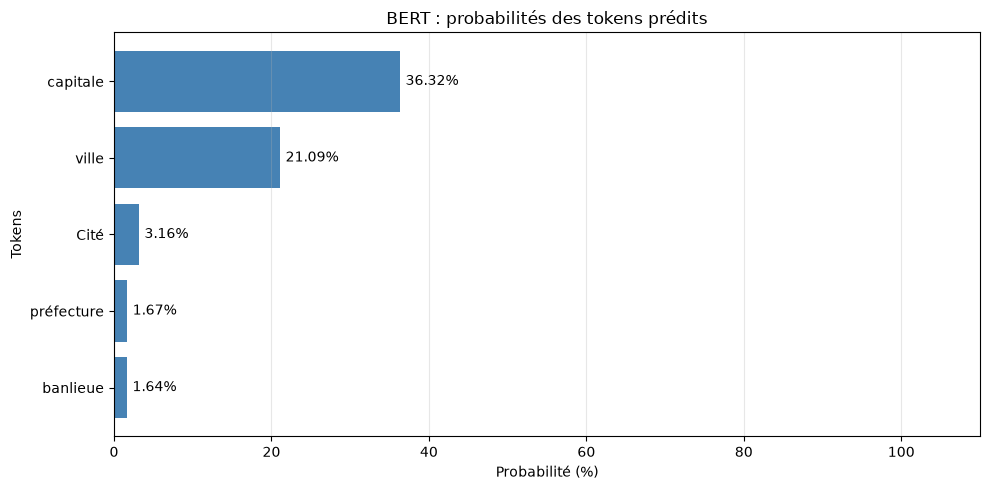

In [11]:
import matplotlib.pyplot as plt

mots_predits = [
    tokenizer_bert.decode([indice.item()]).strip()
    for indice in top_indices
]

probas = [
    probabilite.item() * 100
    for probabilite in top_probabilites
]

plt.figure(figsize=(10, 5))

barres = plt.barh(
    mots_predits,
    probas,
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.bar_label(barres, fmt="%.2f%%", padding=4)

plt.title("BERT : probabilités des tokens prédits")
plt.xlabel("Probabilité (%)")
plt.ylabel("Tokens")
plt.xlim(0, 110)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
def predire_masque(phrase, k=5):

    entrees = tokenizer_bert(
        phrase,
        return_tensors="pt"
    )

    positions = (
        entrees["input_ids"][0]
        == tokenizer_bert.mask_token_id
    ).nonzero(as_tuple=True)[0]

    if len(positions) != 1:
        raise ValueError(
            "La phrase doit contenir exactement un token [MASK]."
        )

    position = positions.item()

    with torch.no_grad():
        sortie = modele_bert(**entrees)

    scores = sortie.logits[0, position, :]

    probabilites = torch.softmax(scores, dim=-1)

    top_probs, top_ids = torch.topk(
        probabilites,
        k=k
    )

    print("Phrase originale :", phrase)
    print("-" * 60)

    for proba, indice in zip(top_probs, top_ids):

        token = tokenizer_bert.decode(
            [indice.item()]
        ).strip()

        resultat = phrase.replace(
            tokenizer_bert.mask_token,
            token
        )

        print(f"{proba.item():.2%} | {resultat}")

    print()

In [13]:
phrases = [
    "Paris est la [MASK] de la France.",
    "Rabat est la [MASK] du Maroc.",
    "La souris mange du [MASK].",
    "La souris est connectée à l'[MASK].",
    "Le professeur explique le cours aux [MASK].",
    "Artificial intelligence is changing the [MASK]."
]

for phrase in phrases:
    predire_masque(phrase)

Phrase originale : Paris est la [MASK] de la France.
------------------------------------------------------------
36.32% | Paris est la capitale de la France.
21.09% | Paris est la ville de la France.
3.16% | Paris est la Cité de la France.
1.67% | Paris est la préfecture de la France.
1.64% | Paris est la banlieue de la France.

Phrase originale : Rabat est la [MASK] du Maroc.
------------------------------------------------------------
86.06% | Rabat est la capitale du Maroc.
5.19% | Rabat est la ville du Maroc.
5.03% | Rabat est la préfecture du Maroc.
0.85% | Rabat est la Rabat du Maroc.
0.58% | Rabat est la capital du Maroc.

Phrase originale : La souris mange du [MASK].
------------------------------------------------------------
13.68% | La souris mange du lait.
7.68% | La souris mange du pain.
7.39% | La souris mange du vin.
3.21% | La souris mange du pois.
2.04% | La souris mange du fruit.

Phrase originale : La souris est connectée à l'[MASK].
--------------------------------

###  Interprétation des résultats

Les résultats montrent que BERT est capable de prédire
des tokens masqués en exploitant le contexte complet
d'une phrase.

Contrairement à GPT, BERT utilise une attention
bidirectionnelle qui permet de consulter les tokens
situés avant et après le masque.

Les expériences réalisées sur plusieurs phrases
illustrent l'importance du contexte dans la compréhension
du langage naturel.

Le modèle multilingue permet également de traiter
des phrases dans différentes langues.

Cette architecture est particulièrement adaptée aux
tâches de compréhension du langage, notamment :

- La classification de textes.
- L'analyse de sentiments.
- La reconnaissance d'entités nommées.
- Les systèmes de questions-réponses.
- La prédiction de tokens masqués.

Cependant, les prédictions ne sont pas toujours correctes
et dépendent du contexte ainsi que des données utilisées
lors du pré-entraînement.

## Comparaison entre GPT et BERT

| Critère | GPT | BERT |
|---|---|---|
| Architecture | Decoder-only | Encoder-only |
| Attention | Causale | Bidirectionnelle |
| Contexte | Tokens précédents | Tokens précédents et suivants |
| Pré-entraînement principal | Next Token Prediction | Masked Language Modeling |
| Tokenisation | BPE | WordPiece |
| Objectif principal | Génération de texte | Compréhension du texte |
| Sortie habituelle | Prédiction du prochain token | Représentations contextualisées |
| Applications | Dialogue, génération, code | Classification, extraction, compréhension |

GPT et BERT reposent tous les deux sur l'architecture
Transformer, mais répondent à des objectifs différents.

GPT est principalement orienté vers la génération
autorégressive de texte, tandis que BERT est principalement
orienté vers la compréhension du contexte linguistique.

## 9. Exercice 1 : Energy Transformer

### 9.1. Objectif

L'objectif de cet exercice est de construire un modèle
Transformer capable de prédire la puissance électrique
moyenne de l'heure suivante à partir des 24 dernières
heures observées.

Nous utilisons le dataset Individual Household Electric
Power Consumption provenant de l'UCI Machine Learning
Repository.

La variable étudiée est Global_active_power,
qui représente la puissance électrique active en kW.

Les mesures sont agrégées par heure afin de construire
une série temporelle horaire.

Source : Hebrail, G. et Berard, A. (2006).
Individual Household Electric Power Consumption.
UCI Machine Learning Repository.
https://doi.org/10.24432/C58K54

In [14]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error
from copy import deepcopy

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

Device : cpu


In [15]:
chemin_dataset = Path("data/household_power_consumption.txt")

assert chemin_dataset.exists(), "Dataset introuvable !"

df_energy = pd.read_csv(
    chemin_dataset,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dimensions :", df_energy.shape)

df_energy.head()

Dimensions : (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [16]:
df_energy.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


In [17]:
df_energy.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [18]:
df_energy["datetime"] = pd.to_datetime(
    df_energy["Date"] + " " + df_energy["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

puissance = pd.to_numeric(
    df_energy["Global_active_power"],
    errors="coerce"
)

puissance.index = pd.DatetimeIndex(
    df_energy["datetime"]
)

horaire = puissance.resample("h").agg(
    ["mean", "count"]
)

serie_energy = horaire["mean"].where(
    horaire["count"] >= 45
)

print("Nombre total d'heures :", len(serie_energy))
print("Heures valides :", serie_energy.notna().sum())
print("Heures manquantes :", serie_energy.isna().sum())

serie_energy.head(10)

Nombre total d'heures : 34589
Heures valides : 34151
Heures manquantes : 438


datetime
2006-12-16 17:00:00         NaN
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
2006-12-16 22:00:00    2.200133
2006-12-16 23:00:00    2.061600
2006-12-17 00:00:00    1.882467
2006-12-17 01:00:00    3.349400
2006-12-17 02:00:00    1.587267
Freq: h, Name: mean, dtype: float64

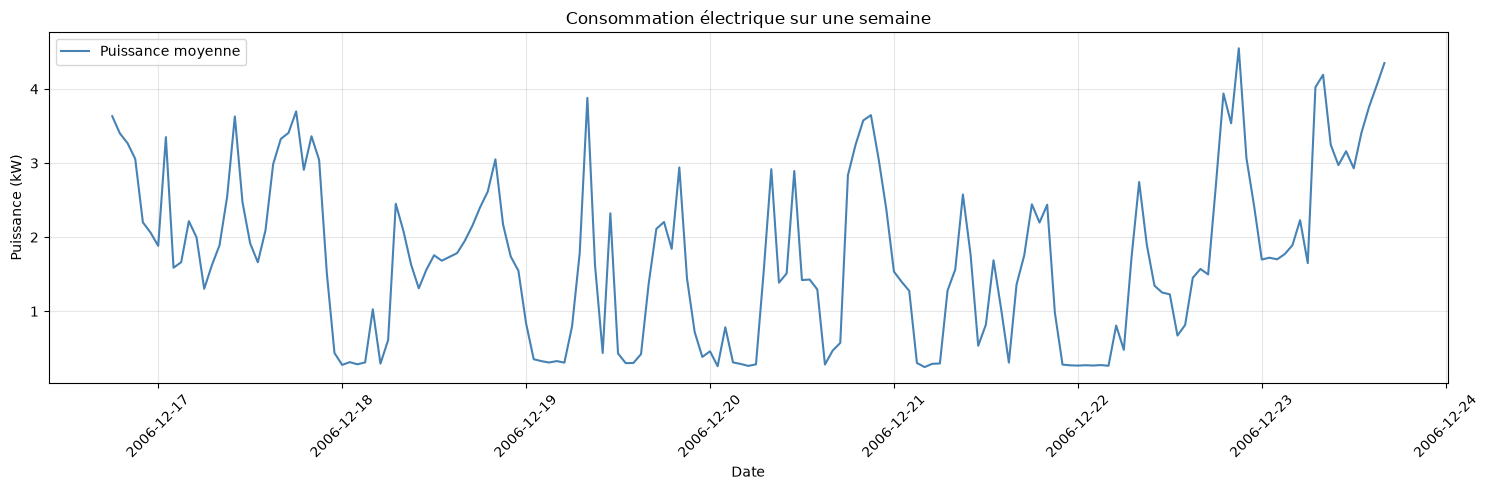

In [19]:
plt.figure(figsize=(15, 5))

plt.plot(
    serie_energy.iloc[:168],
    color="steelblue",
    label="Puissance moyenne"
)

plt.title("Consommation électrique sur une semaine")
plt.xlabel("Date")
plt.ylabel("Puissance (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
n = len(serie_energy)

fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

moyenne = serie_energy.iloc[:fin_train].mean()

ecart_type = serie_energy.iloc[:fin_train].std()

valeurs_energy = (
    (serie_energy - moyenne) / ecart_type
).to_numpy()

print("Nombre total d'heures :", n)
print("Fin entraînement :", fin_train)
print("Fin validation :", fin_val)

print(f"Moyenne train : {moyenne:.4f} kW")
print(f"Écart-type train : {ecart_type:.4f} kW")

Nombre total d'heures : 34589
Fin entraînement : 24212
Fin validation : 29400
Moyenne train : 1.0865 kW
Écart-type train : 0.9287 kW


In [21]:
fenetre = 24

X_energy = []
y_energy = []
dates_cibles = []

for i in range(fenetre, n):

    sequence = valeurs_energy[i - fenetre:i]
    cible = valeurs_energy[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):

        X_energy.append(sequence)
        y_energy.append(cible)
        dates_cibles.append(i)

X_energy = torch.tensor(
    np.array(X_energy),
    dtype=torch.float32
).unsqueeze(-1)

y_energy = torch.tensor(
    np.array(y_energy),
    dtype=torch.float32
).unsqueeze(-1)

dates_cibles = np.array(dates_cibles)

print("Dimensions X :", X_energy.shape)
print("Dimensions y :", y_energy.shape)

Dimensions X : torch.Size([33791, 24, 1])
Dimensions y : torch.Size([33791, 1])


In [22]:
train_mask = dates_cibles < fin_train

val_mask = (
    (dates_cibles >= fin_train) &
    (dates_cibles < fin_val)
)

test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(
        X_energy[train_mask],
        y_energy[train_mask]
    ),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        X_energy[val_mask],
        y_energy[val_mask]
    ),
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(
        X_energy[test_mask],
        y_energy[test_mask]
    ),
    batch_size=64,
    shuffle=False
)

print("Séquences train :", len(train_loader.dataset))
print("Séquences validation :", len(val_loader.dataset))
print("Séquences test :", len(test_loader.dataset))

Séquences train : 23805
Séquences validation : 5054
Séquences test : 4932


In [23]:
X_batch, y_batch = next(iter(train_loader))

print("Dimensions X_batch :", X_batch.shape)
print("Dimensions y_batch :", y_batch.shape)

Dimensions X_batch : torch.Size([64, 24, 1])
Dimensions y_batch : torch.Size([64, 1])


In [24]:
class EnergyTransformer(nn.Module):

    def __init__(self, longueur_max=24):
        super().__init__()

        dimension = 32

        self.projection = nn.Linear(1, dimension)

        self.positions = nn.Embedding(
            longueur_max,
            dimension
        )

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=2
        )

        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):

        longueur = x.size(1)

        x = self.projection(x)

        indices = torch.arange(
            longueur,
            device=x.device
        )

        positions = self.positions(indices)

        x = x + positions.unsqueeze(0)

        representations = self.encodeur(x)

        derniere_position = representations[:, -1, :]

        return self.sortie(derniere_position)


modele_energy = EnergyTransformer(
    longueur_max=fenetre
).to(device)

print(modele_energy)

print("\nNombre de paramètres :", sum(
    p.numel() for p in modele_energy.parameters()
))

EnergyTransformer(
  (projection): Linear(in_features=1, out_features=32, bias=True)
  (positions): Embedding(24, 32)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=32, out_features=1, bias=True)
)

Nombre de paramètres : 26273


In [25]:
modele_energy.eval()

with torch.no_grad():

    sortie = modele_energy(X_batch.to(device))

print("Dimensions entrée :", X_batch.shape)
print("Dimensions sortie :", sortie.shape)

assert sortie.shape == y_batch.shape

print("Architecture validée !")

Dimensions entrée : torch.Size([64, 24, 1])
Dimensions sortie : torch.Size([64, 1])
Architecture validée !


In [26]:
critere_energy = nn.MSELoss()

optimiseur_energy = torch.optim.Adam(
    modele_energy.parameters(),
    lr=0.001
)

epochs_energy = 20

historique_train_energy = []
historique_val_energy = []

meilleure_perte_val = float("inf")
meilleur_etat = None
meilleure_epoch = 0

In [27]:
for epoch in range(epochs_energy):

    # Entraînement
    modele_energy.train()

    perte_train = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimiseur_energy.zero_grad()

        predictions = modele_energy(X_batch)

        perte = critere_energy(predictions, y_batch)

        perte.backward()

        optimiseur_energy.step()

        perte_train += perte.item() * X_batch.size(0)

    perte_train /= len(train_loader.dataset)

    # Validation
    modele_energy.eval()

    perte_val = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = modele_energy(X_batch)

            perte = critere_energy(
                predictions,
                y_batch
            )

            perte_val += perte.item() * X_batch.size(0)

    perte_val /= len(val_loader.dataset)

    historique_train_energy.append(perte_train)
    historique_val_energy.append(perte_val)

    # Conservation du meilleur modèle
    if perte_val < meilleure_perte_val:

        meilleure_perte_val = perte_val

        meilleur_etat = deepcopy(
            modele_energy.state_dict()
        )

        meilleure_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1:02d}/{epochs_energy} | "
        f"Train Loss : {perte_train:.6f} | "
        f"Val Loss : {perte_val:.6f}",
        flush=True
    )

# Restaurer le meilleur modèle
modele_energy.load_state_dict(meilleur_etat)

print("\nMeilleure epoch :", meilleure_epoch)

print(
    f"Meilleure perte validation : "
    f"{meilleure_perte_val:.6f}"
)

Epoch 01/20 | Train Loss : 0.462738 | Val Loss : 0.395615
Epoch 02/20 | Train Loss : 0.425287 | Val Loss : 0.399132
Epoch 03/20 | Train Loss : 0.419783 | Val Loss : 0.387957
Epoch 04/20 | Train Loss : 0.417401 | Val Loss : 0.383799
Epoch 05/20 | Train Loss : 0.414519 | Val Loss : 0.382102
Epoch 06/20 | Train Loss : 0.411241 | Val Loss : 0.384014
Epoch 07/20 | Train Loss : 0.410817 | Val Loss : 0.382927
Epoch 08/20 | Train Loss : 0.411101 | Val Loss : 0.384264
Epoch 09/20 | Train Loss : 0.407600 | Val Loss : 0.379168
Epoch 10/20 | Train Loss : 0.407257 | Val Loss : 0.378175
Epoch 11/20 | Train Loss : 0.405970 | Val Loss : 0.380077
Epoch 12/20 | Train Loss : 0.401909 | Val Loss : 0.376959
Epoch 13/20 | Train Loss : 0.403665 | Val Loss : 0.376386
Epoch 14/20 | Train Loss : 0.399866 | Val Loss : 0.376383
Epoch 15/20 | Train Loss : 0.402072 | Val Loss : 0.378417
Epoch 16/20 | Train Loss : 0.397604 | Val Loss : 0.375601
Epoch 17/20 | Train Loss : 0.399124 | Val Loss : 0.377083
Epoch 18/20 | 

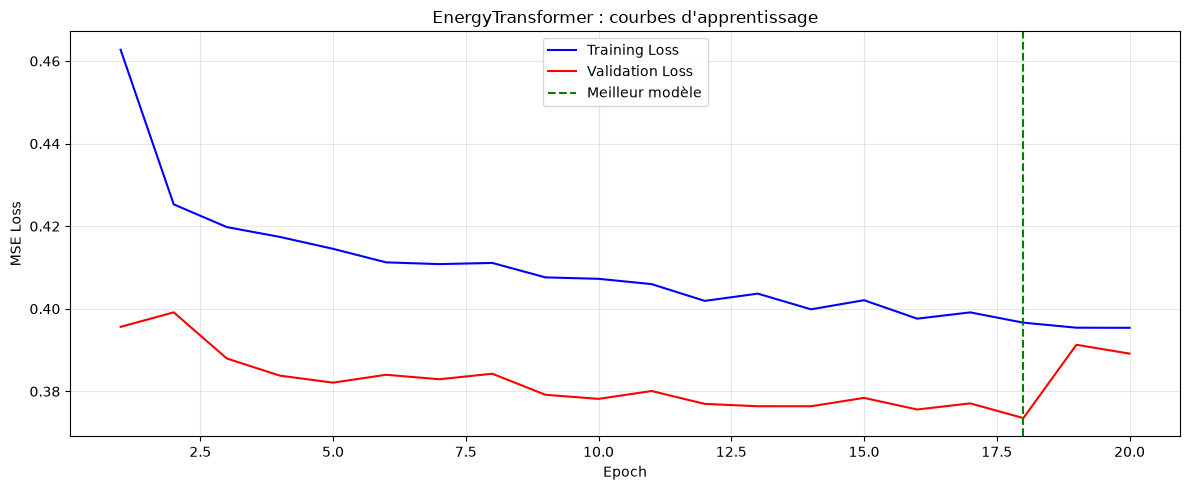

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, epochs_energy + 1),
    historique_train_energy,
    label="Training Loss",
    color="blue"
)

plt.plot(
    range(1, epochs_energy + 1),
    historique_val_energy,
    label="Validation Loss",
    color="red"
)

plt.axvline(
    meilleure_epoch,
    color="green",
    linestyle="--",
    label="Meilleur modèle"
)

plt.title("EnergyTransformer : courbes d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
modele_energy.eval()

predictions_energy = []
reelles_energy = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        predictions = modele_energy(
            X_batch.to(device)
        )

        predictions_energy.append(
            predictions.cpu().numpy()
        )

        reelles_energy.append(
            y_batch.numpy()
        )

predictions_energy = np.concatenate(
    predictions_energy
).reshape(-1)

reelles_energy = np.concatenate(
    reelles_energy
).reshape(-1)

# Retour à l'échelle originale
predictions_kw = (
    predictions_energy * ecart_type + moyenne
)

reelles_kw = (
    reelles_energy * ecart_type + moyenne
)

mae_energy = mean_absolute_error(
    reelles_kw,
    predictions_kw
)

rmse_energy = np.sqrt(
    mean_squared_error(
        reelles_kw,
        predictions_kw
    )
)

print(f"MAE Transformer : {mae_energy:.4f} kW")
print(f"RMSE Transformer : {rmse_energy:.4f} kW")

MAE Transformer : 0.3467 kW
RMSE Transformer : 0.4912 kW


In [30]:
X_test_energy = X_energy[test_mask]

# Persistance : dernière heure
persistance = X_test_energy[:, -1, 0].numpy()

# Référence journalière : 24 heures auparavant
reference_jour = X_test_energy[:, 0, 0].numpy()

# Dénormalisation
persistance_kw = persistance * ecart_type + moyenne

reference_jour_kw = reference_jour * ecart_type + moyenne

mae_persistance = mean_absolute_error(
    reelles_kw, persistance_kw
)

rmse_persistance = np.sqrt(
    mean_squared_error(reelles_kw, persistance_kw)
)

mae_jour = mean_absolute_error(
    reelles_kw, reference_jour_kw
)

rmse_jour = np.sqrt(
    mean_squared_error(reelles_kw, reference_jour_kw)
)

In [31]:
comparaison_energy = pd.DataFrame({

    "Modèle": [
        "Persistance",
        "Référence journalière",
        "EnergyTransformer"
    ],

    "MAE (kW)": [
        mae_persistance,
        mae_jour,
        mae_energy
    ],

    "RMSE (kW)": [
        rmse_persistance,
        rmse_jour,
        rmse_energy
    ]
})

comparaison_energy = comparaison_energy.sort_values(
    "MAE (kW)"
)

comparaison_energy.style.format({
    "MAE (kW)": "{:.4f}",
    "RMSE (kW)": "{:.4f}"
})

,Modèle,MAE (kW),RMSE (kW)
2,EnergyTransformer,0.3467,0.4912
0,Persistance,0.3892,0.5884
1,Référence journalière,0.5133,0.7639


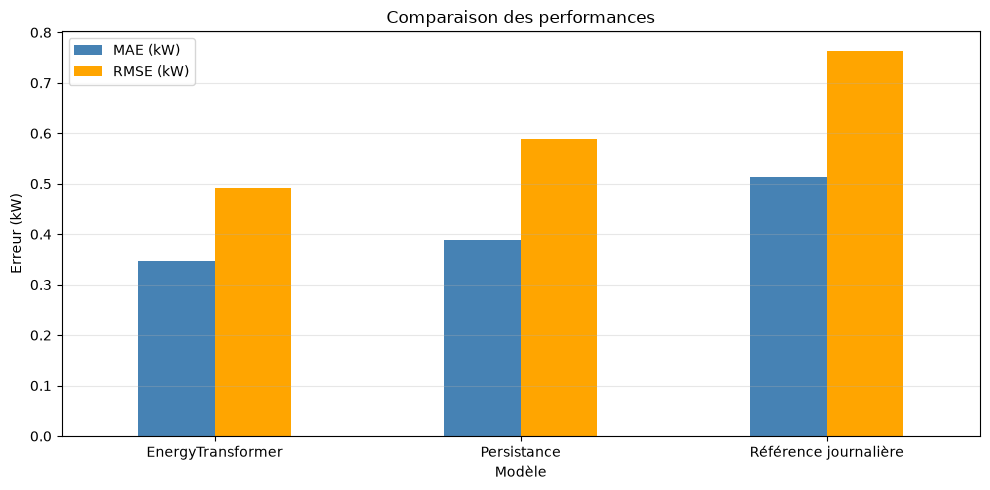

In [32]:
comparaison_energy.set_index("Modèle").plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "orange"]
)

plt.title("Comparaison des performances")
plt.ylabel("Erreur (kW)")
plt.xlabel("Modèle")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

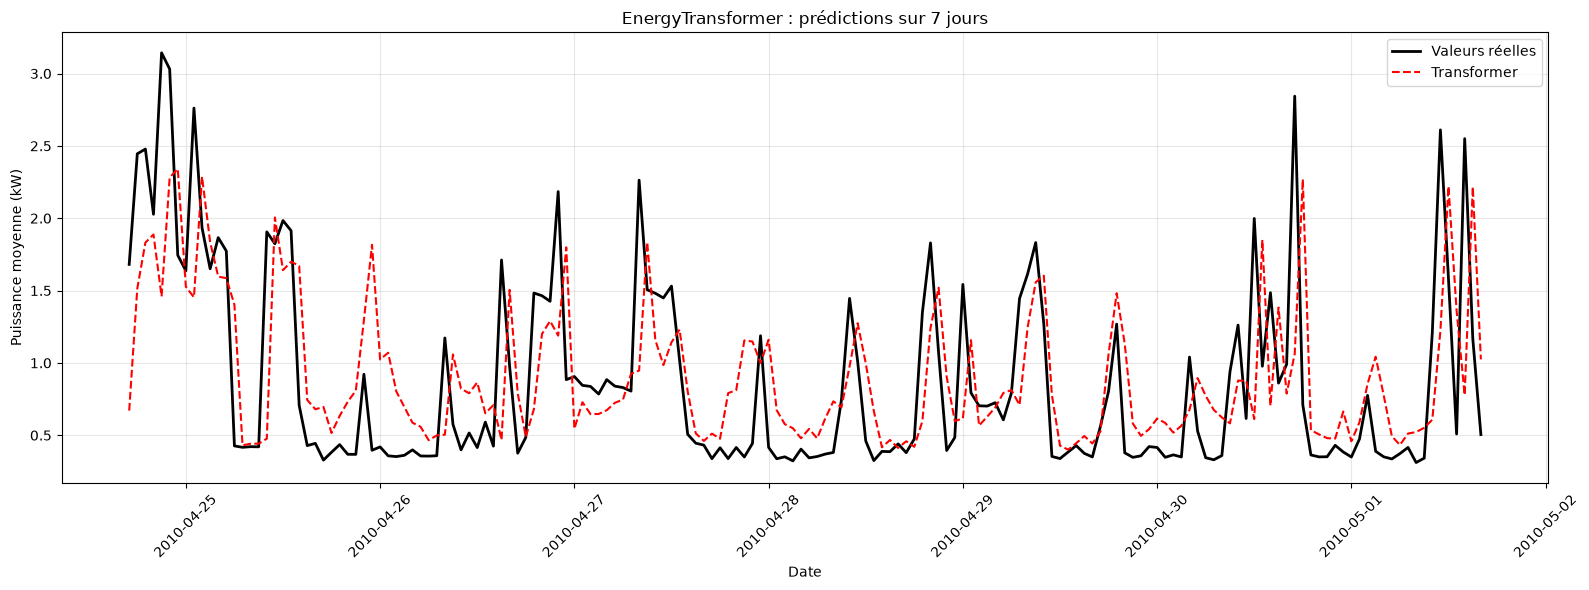

In [33]:
dates_test = serie_energy.index[
    dates_cibles[test_mask]
]

resultats_energy = pd.DataFrame({

    "Réel": reelles_kw,
    "Transformer": predictions_kw,
    "Persistance": persistance_kw,
    "Référence journalière": reference_jour_kw

}, index=dates_test)

# Recherche de 168 heures consécutives
debut = None

for i in range(len(resultats_energy) - 167):

    intervalle = (
        resultats_energy.index[i + 167]
        - resultats_energy.index[i]
    )

    if intervalle == pd.Timedelta(hours=167):

        debut = i
        break

if debut is not None:

    semaine = resultats_energy.iloc[debut:debut + 168]

else:

    semaine = resultats_energy.loc[
        resultats_energy.index[0]:
        resultats_energy.index[0] + pd.Timedelta(hours=167)
    ].asfreq("h")

    print("Certaines heures de cette semaine sont manquantes.")

plt.figure(figsize=(16, 6))

plt.plot(
    semaine.index,
    semaine["Réel"],
    color="black",
    linewidth=2,
    label="Valeurs réelles"
)

plt.plot(
    semaine.index,
    semaine["Transformer"],
    color="red",
    linestyle="--",
    label="Transformer"
)

plt.title("EnergyTransformer : prédictions sur 7 jours")
plt.xlabel("Date")
plt.ylabel("Puissance moyenne (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10. Exercice 2 : Implémentation d'un Mini-GPT

### 10.1. Objectif

L'objectif de cet exercice est de construire et d'entraîner
un petit modèle de type GPT à partir de zéro.

Contrairement au modèle GPT-2 pré-entraîné utilisé
précédemment, notre Mini-GPT apprend directement à partir
d'un corpus de texte.

Nous utilisons une tokenisation par caractères afin
de simplifier la préparation des données.

Le modèle repose sur une architecture Transformer
autorégressive utilisant un mécanisme d'attention causale.

Chaque position apprend à prédire le caractère suivant
à partir des caractères précédents.

In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.request import urlopen
from copy import deepcopy

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Limiter le nombre de threads sur CPU
if device.type == "cpu":
    torch.set_num_threads(4)

print("Device :", device)

Device : cpu


In [45]:
from pathlib import Path
from urllib.request import urlopen

chemin_corpus = Path("data/corpus.txt")

chemin_corpus.parent.mkdir(
    parents=True,
    exist_ok=True
)

if not chemin_corpus.exists():

    url = "https://lingobound.com/library/around-the-world-in-eighty-days/fr/around-the-world-in-eighty-days-fr.txt"

    with urlopen(url, timeout=60) as response:
        texte_brut = response.read().decode("utf-8-sig")

    chemin_corpus.write_text(
        texte_brut,
        encoding="utf-8"
    )

    print("Corpus téléchargé avec succès !")

else:
    print("Le corpus existe déjà.")

print("Taille du fichier :", chemin_corpus.stat().st_size, "octets")

Le corpus existe déjà.
Taille du fichier : 472729 octets


In [44]:
texte_corpus = chemin_corpus.read_text(
    encoding="utf-8-sig"
)

print("Nombre de caractères :", len(texte_corpus))
print("Taille du fichier :", chemin_corpus.stat().st_size)

print("\nExtrait du corpus :\n")
print(texte_corpus[:500])

assert len(texte_corpus) >= 150000, "Corpus trop court."

print("\nCorpus validé avec succès !")

Nombre de caractères : 449079
Taille du fichier : 472729

Extrait du corpus :

The Project Gutenberg eBook of Le Tour du monde en quatre-vingts jours
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before

Corpus validé avec succès !


In [46]:
texte_corpus = chemin_corpus.read_text(
    encoding="utf-8-sig"
)

lignes = texte_corpus.splitlines()

# Supprimer l'en-tête de Project Gutenberg
debut = next(
    (
        i + 1 for i, ligne in enumerate(lignes)
        if ligne.strip().startswith("*** START OF")
    ),
    0
)

# Supprimer les informations de fin
fin = next(
    (
        i for i, ligne in enumerate(lignes)
        if ligne.strip().startswith("*** END OF")
    ),
    len(lignes)
)

texte_corpus = "\n".join(lignes[debut:fin]).strip()

print("Nombre de caractères après nettoyage :", len(texte_corpus))

# Limiter la taille du corpus pour l'entraînement sur CPU
texte_corpus = texte_corpus[:150000]

print("Nombre de caractères retenus :", len(texte_corpus))

print("\nExtrait du corpus nettoyé :\n")
print(texte_corpus[:500])

Nombre de caractères après nettoyage : 429414
Nombre de caractères retenus : 150000

Extrait du corpus nettoyé :

Au lecteur.

    Ce livre électronique reproduit dans son intégralité la
    version originale.

    La ponctuation n'a pas été modifiée hormis quelques corrections
    mineures.

    L'orthographe a été conservée. Seules les erreurs évidentes de
    typographie ou d'impression ont été corrigées. La liste de ces
    modifications se trouve à la fin du texte.




  LE
  TOUR DU MONDE
  EN QUATRE-VINGTS JOURS




  —LES VOYAGES EXTRAORDINAIRES—


  [Illustration]


  —COLLECTION J. HETZEL—




  L


In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from pathlib import Path
from copy import deepcopy
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if device.type == "cpu":
    torch.set_num_threads(4)

print("Device :", device)

Device : cpu


In [48]:
chemin_bert = Path("data/corpus.txt")

# Si le fichier se trouve à côté du notebook
if not chemin_bert.exists():
    chemin_bert = Path("corpus.txt")

texte_bert_corpus = chemin_bert.read_text(
    encoding="utf-8-sig"
)

lignes = texte_bert_corpus.splitlines()

debut = next(
    (
        i + 1 for i, ligne in enumerate(lignes)
        if ligne.strip().startswith("*** START OF")
    ),
    0
)

fin = next(
    (
        i for i, ligne in enumerate(lignes)
        if ligne.strip().startswith("*** END OF")
    ),
    len(lignes)
)

texte_bert_corpus = " ".join(lignes[debut:fin])

texte_bert_corpus = re.sub(
    r"\s+", " ", texte_bert_corpus
).strip()

print("Nombre de caractères :", len(texte_bert_corpus))
print(texte_bert_corpus[:500])

Nombre de caractères : 424389
Au lecteur. Ce livre électronique reproduit dans son intégralité la version originale. La ponctuation n'a pas été modifiée hormis quelques corrections mineures. L'orthographe a été conservée. Seules les erreurs évidentes de typographie ou d'impression ont été corrigées. La liste de ces modifications se trouve à la fin du texte. LE TOUR DU MONDE EN QUATRE-VINGTS JOURS —LES VOYAGES EXTRAORDINAIRES— [Illustration] —COLLECTION J. HETZEL— LES VOYAGES EXTRAORDINAIRES COURONNÉS PAR L'ACADÉMIE LE TOUR D


In [49]:
def tokeniser_bert(texte):

    return re.findall(
        r"\w+|[^\w\s]",
        texte.lower()
    )


phrases_bert = re.split(
    r"(?<=[.!?])\s+",
    texte_bert_corpus
)

phrases_tokenisees = [
    tokeniser_bert(phrase)
    for phrase in phrases_bert
]

# Conserver les phrases de longueur suffisante
phrases_tokenisees = [
    phrase for phrase in phrases_tokenisees
    if 5 <= len(phrase) <= 30
]

# Supprimer les doublons
phrases_tokenisees = [
    list(phrase)
    for phrase in dict.fromkeys(
        tuple(p) for p in phrases_tokenisees
    )
]

# Limiter le corpus pour un entraînement sur CPU
phrases_tokenisees = phrases_tokenisees[:3000]

print("Nombre de phrases :", len(phrases_tokenisees))

print("\nExemples :")

for phrase in phrases_tokenisees[:5]:
    print(phrase)

Nombre de phrases : 3000

Exemples :
['ce', 'livre', 'électronique', 'reproduit', 'dans', 'son', 'intégralité', 'la', 'version', 'originale', '.']
['la', 'ponctuation', 'n', "'", 'a', 'pas', 'été', 'modifiée', 'hormis', 'quelques', 'corrections', 'mineures', '.']
['l', "'", 'orthographe', 'a', 'été', 'conservée', '.']
['seules', 'les', 'erreurs', 'évidentes', 'de', 'typographie', 'ou', 'd', "'", 'impression', 'ont', 'été', 'corrigées', '.']
['la', 'liste', 'de', 'ces', 'modifications', 'se', 'trouve', 'à', 'la', 'fin', 'du', 'texte', '.']


In [50]:
rng = np.random.default_rng(42)

indices_bert = rng.permutation(
    len(phrases_tokenisees)
)

n_train_bert = int(
    0.9 * len(phrases_tokenisees)
)

phrases_train_bert = [
    phrases_tokenisees[i]
    for i in indices_bert[:n_train_bert]
]

phrases_val_bert = [
    phrases_tokenisees[i]
    for i in indices_bert[n_train_bert:]
]

print("Phrases train :", len(phrases_train_bert))
print("Phrases validation :", len(phrases_val_bert))

Phrases train : 2700
Phrases validation : 300


In [51]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

tokens_speciaux = [
    "[PAD]",
    "[UNK]",
    "[CLS]",
    "[SEP]",
    "[MASK]"
]

frequences = Counter(
    mot
    for phrase in phrases_train_bert
    for mot in phrase
)

# Conserver les tokens apparaissant au moins deux fois
mots_bert = sorted([
    mot
    for mot, frequence in frequences.items()
    if frequence >= 2
])

vocabulaire_bert = tokens_speciaux + mots_bert

stoi_bert = {
    mot: i
    for i, mot in enumerate(vocabulaire_bert)
}

itos_bert = {
    i: mot
    for mot, i in stoi_bert.items()
}

taille_vocabulaire_bert = len(vocabulaire_bert)

print("Taille du vocabulaire :", taille_vocabulaire_bert)

print("\nTokens spéciaux :")

for token in tokens_speciaux:
    print(token, ":", stoi_bert[token])

Taille du vocabulaire : 2220

Tokens spéciaux :
[PAD] : 0
[UNK] : 1
[CLS] : 2
[SEP] : 3
[MASK] : 4


In [52]:
longueur_bert = 32

def encoder_bert(phrase):

    ids = [
        stoi_bert.get(mot, UNK)
        for mot in phrase[:longueur_bert - 2]
    ]

    ids = [CLS] + ids + [SEP]

    ids += [PAD] * (longueur_bert - len(ids))

    return ids


def decoder_bert(ids):

    return " ".join(
        itos_bert[int(i)]
        for i in ids
    )

In [53]:
train_ids_bert = torch.tensor(
    [
        encoder_bert(phrase)
        for phrase in phrases_train_bert
    ],
    dtype=torch.long
)

val_ids_bert = torch.tensor(
    [
        encoder_bert(phrase)
        for phrase in phrases_val_bert
    ],
    dtype=torch.long
)

print("Dimensions train :", train_ids_bert.shape)
print("Dimensions validation :", val_ids_bert.shape)

print("\nPremière séquence :")
print(train_ids_bert[0])

print("\nPhrase décodée :")
print(decoder_bert(train_ids_bert[0]))

Dimensions train : torch.Size([2700, 32])
Dimensions validation : torch.Size([300, 32])

Première séquence :
tensor([   2, 1006, 1231,    6,   97, 1246,  340, 1246, 1359,   11,    3,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0])

Phrase décodée :
[CLS] je n ' ai ni cartes ni partenaires . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [54]:
def masquer_tokens(input_ids):

    input_ids = input_ids.clone()

    labels = input_ids.clone()

    # Le masque de padding est calculé avant corruption
    padding_mask = input_ids.eq(PAD)

    # Exclure les tokens spéciaux
    tokens_ordinaires = input_ids >= 5

    positions_selectionnees = (
        torch.rand(input_ids.shape, device=input_ids.device) < 0.15
    ) & tokens_ordinaires

    # Garantir au moins une position sélectionnée
    for i in range(input_ids.size(0)):

        if not positions_selectionnees[i].any():

            positions_valides = torch.where(
                tokens_ordinaires[i]
            )[0]

            if len(positions_valides) > 0:

                indice = torch.randint(
                    len(positions_valides),
                    (1,),
                    device=input_ids.device
                )

                position = positions_valides[indice]

                positions_selectionnees[i, position] = True

    # Ignorer les positions non sélectionnées
    labels[~positions_selectionnees] = -100

    probabilites = torch.rand(
        input_ids.shape,
        device=input_ids.device
    )

    # 80 % : remplacement par MASK
    positions_mask = (
        positions_selectionnees
        & (probabilites < 0.8)
    )

    input_ids[positions_mask] = MASK

    # 10 % : remplacement aléatoire
    positions_aleatoires = (
        positions_selectionnees
        & (probabilites >= 0.8)
        & (probabilites < 0.9)
    )

    tokens_aleatoires = torch.randint(
        5,
        taille_vocabulaire_bert,
        input_ids.shape,
        device=input_ids.device
    )

    input_ids[positions_aleatoires] = (
        tokens_aleatoires[positions_aleatoires]
    )

    # Les 10 % restants sont conservés

    return (
        input_ids,
        labels,
        padding_mask,
        positions_selectionnees
    )

In [55]:
exemple_bert = train_ids_bert[:3]

(
    entrees_masquees,
    labels_bert,
    padding_mask_bert,
    positions_selectionnees
) = masquer_tokens(exemple_bert)

for i in range(len(exemple_bert)):

    print("=" * 70)

    print("Phrase originale :")
    print(decoder_bert(exemple_bert[i]))

    print("\nPhrase corrompue :")
    print(decoder_bert(entrees_masquees[i]))

    print("\nTokens à prédire :")

    print([
        itos_bert[token.item()]
        for token in labels_bert[i]
        if token.item() != -100
    ])

    print()

# Vérifications
assert torch.equal(
    labels_bert != -100,
    positions_selectionnees
)

assert not (
    positions_selectionnees & (exemple_bert < 5)
).any()

assert torch.equal(
    labels_bert[positions_selectionnees],
    exemple_bert[positions_selectionnees]
)

print("Masquage validé !")

Phrase originale :
[CLS] je n ' ai ni cartes ni partenaires . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Phrase corrompue :
[CLS] je n ' ai ni cartes ni partenaires [MASK] [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tokens à prédire :
['.']

Phrase originale :
[CLS] — et il se porte bien , mr . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Phrase corrompue :
[CLS] — et il se porte bien , [MASK] . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tokens à prédire :
['mr']

Phrase originale :
[CLS] passepartout , [UNK] par cette [UNK] , devant craindre d ' être compromis , se [UNK] sans doute à lui , fix . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PA

###  Architecture du Mini-BERT

Le modèle est composé des éléments suivants :

- Embeddings de tokens de dimension 64.
- Embeddings positionnels de dimension 64.
- Deux couches Transformer Encoder.
- Quatre têtes d'attention par couche.
- Un mécanisme d'attention bidirectionnelle.
- Un masque de padding.
- Une projection linéaire vers le vocabulaire.

Contrairement au Mini-GPT, aucun masque causal
n'est utilisé.

Le modèle peut donc exploiter le contexte situé
avant et après chaque position.

In [56]:
class MiniBERT(nn.Module):

    def __init__(
        self,
        taille_vocabulaire,
        longueur_max=32,
        dimension=64,
        nhead=4
    ):

        super().__init__()

        self.embedding_tokens = nn.Embedding(
            taille_vocabulaire,
            dimension,
            padding_idx=PAD
        )

        self.embedding_positions = nn.Embedding(
            longueur_max,
            dimension
        )

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=nhead,
            dim_feedforward=256,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=2,
            enable_nested_tensor=False
        )

        self.norm_finale = nn.LayerNorm(dimension)

        self.sortie = nn.Linear(
            dimension,
            taille_vocabulaire
        )

    def forward(self, input_ids, padding_mask):

        B, T = input_ids.shape

        positions = torch.arange(
            T,
            device=input_ids.device
        )

        x = (
            self.embedding_tokens(input_ids)
            + self.embedding_positions(positions)
        )

        representations = self.encodeur(
            x,
            src_key_padding_mask=padding_mask
        )

        representations = self.norm_finale(
            representations
        )

        logits = self.sortie(representations)

        return logits


modele_mini_bert = MiniBERT(
    taille_vocabulaire=taille_vocabulaire_bert
).to(device)

print(modele_mini_bert)

print("\nNombre de paramètres :", sum(
    p.numel()
    for p in modele_mini_bert.parameters()
))

MiniBERT(
  (embedding_tokens): Embedding(2220, 64, padding_idx=0)
  (embedding_positions): Embedding(32, 64)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm_finale): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (sortie): Linear(in_features=64, out_features=2220, bias=True)
)

Nombre de paramètre

In [57]:
modele_mini_bert.eval()

with torch.no_grad():

    logits_bert = modele_mini_bert(
        entrees_masquees.to(device),
        padding_mask_bert.to(device)
    )

print("Entrées :", entrees_masquees.shape)
print("Padding mask :", padding_mask_bert.shape)
print("Logits :", logits_bert.shape)
print("Labels :", labels_bert.shape)

assert logits_bert.shape == (
    3,
    longueur_bert,
    taille_vocabulaire_bert
)

print("\nArchitecture validée !")

Entrées : torch.Size([3, 32])
Padding mask : torch.Size([3, 32])
Logits : torch.Size([3, 32, 2220])
Labels : torch.Size([3, 32])

Architecture validée !


In [58]:
modele_mini_bert.eval()

# Sélectionner une phrase contenant du padding
indices_padding = torch.where(
    train_ids_bert.eq(PAD).any(dim=1)
)[0]

assert len(indices_padding) > 0

sequence_originale = train_ids_bert[
    indices_padding[:1]
].clone().to(device)

masque_padding_test = sequence_originale.eq(PAD)

sequence_modifiee = sequence_originale.clone()

# Modifier uniquement les valeurs de padding
sequence_modifiee[masque_padding_test] = torch.randint(
    5,
    taille_vocabulaire_bert,
    (int(masque_padding_test.sum().item()),),
    device=device
)

with torch.no_grad():

    logits_originaux = modele_mini_bert(
        sequence_originale,
        masque_padding_test
    )

    logits_modifies = modele_mini_bert(
        sequence_modifiee,
        masque_padding_test
    )

positions_utiles = ~masque_padding_test

difference = torch.max(
    torch.abs(
        logits_originaux[positions_utiles]
        - logits_modifies[positions_utiles]
    )
).item()

print("Différence maximale :", difference)

assert torch.allclose(
    logits_originaux[positions_utiles],
    logits_modifies[positions_utiles],
    atol=1e-5,
    rtol=1e-5
)

print("Test réussi : le masque de padding fonctionne !")

Différence maximale : 0.0
Test réussi : le masque de padding fonctionne !


In [59]:
batch_size_bert = 32

train_loader_bert = DataLoader(
    TensorDataset(train_ids_bert),
    batch_size=batch_size_bert,
    shuffle=True
)

# Masquage fixe pour la validation
val_input_bert, val_labels_bert, val_padding_bert, _ = (
    masquer_tokens(val_ids_bert)
)

val_loader_bert = DataLoader(
    TensorDataset(
        val_input_bert,
        val_labels_bert,
        val_padding_bert
    ),
    batch_size=batch_size_bert,
    shuffle=False
)

print("Batches train :", len(train_loader_bert))
print("Batches validation :", len(val_loader_bert))

Batches train : 85
Batches validation : 10


In [60]:
critere_mini_bert = nn.CrossEntropyLoss(
    ignore_index=-100
)

optimiseur_mini_bert = torch.optim.AdamW(
    modele_mini_bert.parameters(),
    lr=0.001
)

epochs_bert = 30

historique_train_bert = []
historique_val_bert = []
historique_accuracy_bert = []

meilleure_val_bert = float("inf")
meilleur_etat_bert = None

In [61]:
@torch.no_grad()
def evaluer_mini_bert():

    modele_mini_bert.eval()

    perte_totale = 0
    corrects = 0
    total = 0

    for input_ids, labels, padding_mask in val_loader_bert:

        input_ids = input_ids.to(device)
        labels = labels.to(device)
        padding_mask = padding_mask.to(device)

        logits = modele_mini_bert(
            input_ids,
            padding_mask
        )

        positions_valides = labels != -100

        nombre_tokens = positions_valides.sum().item()

        if nombre_tokens == 0:
            continue

        perte = critere_mini_bert(
            logits.reshape(-1, taille_vocabulaire_bert),
            labels.reshape(-1)
        )

        predictions = logits.argmax(dim=-1)

        corrects += (
            predictions[positions_valides]
            == labels[positions_valides]
        ).sum().item()

        total += nombre_tokens

        perte_totale += perte.item() * nombre_tokens

    return (
        perte_totale / total,
        corrects / total
    )

In [62]:
for epoch in range(epochs_bert):

    modele_mini_bert.train()

    perte_train = 0
    total_tokens = 0

    for (input_ids,) in train_loader_bert:

        input_ids = input_ids.to(device)

        (
            input_masque,
            labels,
            padding_mask,
            positions
        ) = masquer_tokens(input_ids)

        nombre_tokens = positions.sum().item()

        if nombre_tokens == 0:
            continue

        optimiseur_mini_bert.zero_grad()

        logits = modele_mini_bert(
            input_masque,
            padding_mask
        )

        perte = critere_mini_bert(
            logits.reshape(-1, taille_vocabulaire_bert),
            labels.reshape(-1)
        )

        perte.backward()

        torch.nn.utils.clip_grad_norm_(
            modele_mini_bert.parameters(),
            max_norm=1.0
        )

        optimiseur_mini_bert.step()

        perte_train += perte.item() * nombre_tokens
        total_tokens += nombre_tokens

    perte_train /= total_tokens

    perte_val, accuracy_val = evaluer_mini_bert()

    historique_train_bert.append(perte_train)
    historique_val_bert.append(perte_val)
    historique_accuracy_bert.append(accuracy_val)

    if perte_val < meilleure_val_bert:

        meilleure_val_bert = perte_val

        meilleur_etat_bert = deepcopy(
            modele_mini_bert.state_dict()
        )

    print(
        f"Epoch {epoch + 1:02d}/{epochs_bert} | "
        f"Train Loss : {perte_train:.4f} | "
        f"Val Loss : {perte_val:.4f} | "
        f"Accuracy : {accuracy_val:.2%}",
        flush=True
    )

modele_mini_bert.load_state_dict(
    meilleur_etat_bert
)

print("\nEntraînement terminé !")

Epoch 01/30 | Train Loss : 6.2832 | Val Loss : 5.3798 | Accuracy : 11.29%
Epoch 02/30 | Train Loss : 5.7462 | Val Loss : 5.2004 | Accuracy : 15.36%
Epoch 03/30 | Train Loss : 5.4918 | Val Loss : 5.0368 | Accuracy : 16.61%
Epoch 04/30 | Train Loss : 5.4105 | Val Loss : 4.9457 | Accuracy : 17.87%
Epoch 05/30 | Train Loss : 5.3410 | Val Loss : 4.8729 | Accuracy : 18.81%
Epoch 06/30 | Train Loss : 5.1742 | Val Loss : 4.7899 | Accuracy : 20.85%
Epoch 07/30 | Train Loss : 5.1356 | Val Loss : 4.7141 | Accuracy : 19.59%
Epoch 08/30 | Train Loss : 5.0576 | Val Loss : 4.6182 | Accuracy : 21.79%
Epoch 09/30 | Train Loss : 4.9234 | Val Loss : 4.5456 | Accuracy : 22.26%
Epoch 10/30 | Train Loss : 4.8386 | Val Loss : 4.5123 | Accuracy : 22.41%
Epoch 11/30 | Train Loss : 4.8378 | Val Loss : 4.4653 | Accuracy : 24.76%
Epoch 12/30 | Train Loss : 4.7603 | Val Loss : 4.4146 | Accuracy : 25.39%
Epoch 13/30 | Train Loss : 4.7338 | Val Loss : 4.3824 | Accuracy : 25.08%
Epoch 14/30 | Train Loss : 4.6031 | Va

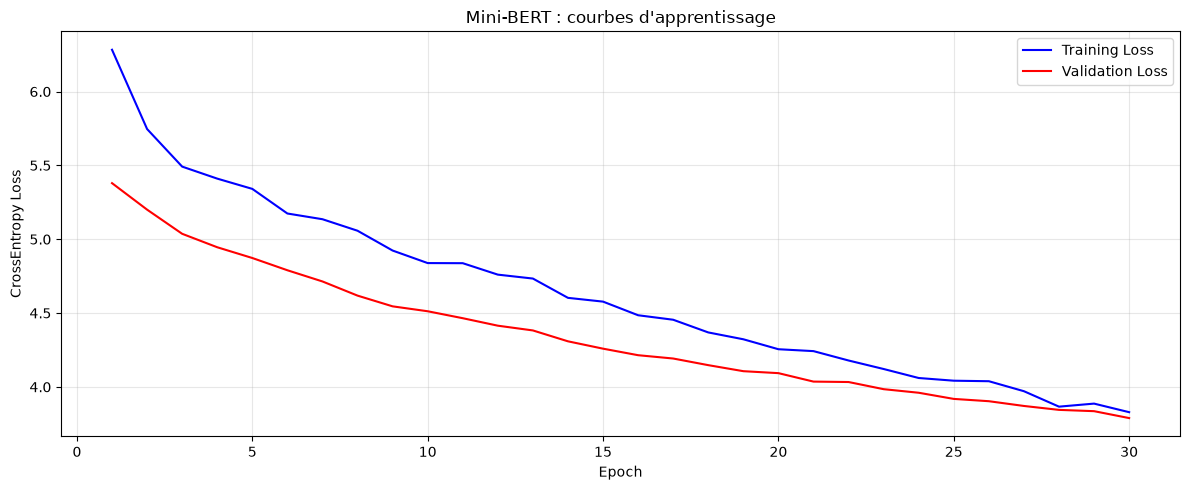

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, epochs_bert + 1),
    historique_train_bert,
    label="Training Loss",
    color="blue"
)

plt.plot(
    range(1, epochs_bert + 1),
    historique_val_bert,
    label="Validation Loss",
    color="red"
)

plt.title("Mini-BERT : courbes d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

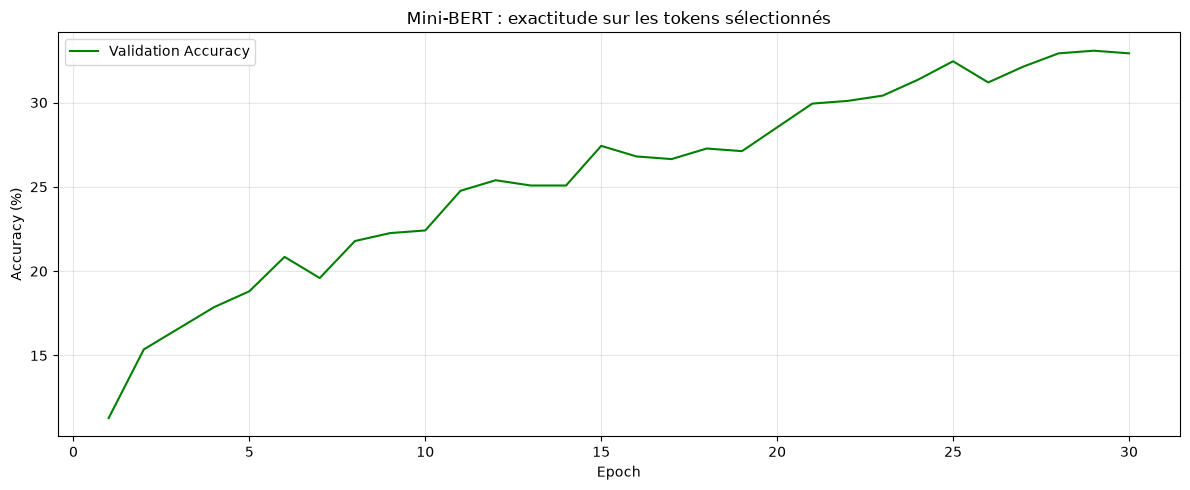

In [64]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, epochs_bert + 1),
    np.array(historique_accuracy_bert) * 100,
    color="green",
    label="Validation Accuracy"
)

plt.title("Mini-BERT : exactitude sur les tokens sélectionnés")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
perte_finale_bert, accuracy_finale_bert = (
    evaluer_mini_bert()
)

print(f"Validation Loss : {perte_finale_bert:.4f}")

print(f"Validation Accuracy : {accuracy_finale_bert:.2%}")

print("Nombre de paramètres :", sum(
    p.numel()
    for p in modele_mini_bert.parameters()
))

Validation Loss : 3.7889
Validation Accuracy : 32.92%
Nombre de paramètres : 388524


In [66]:
@torch.no_grad()
def predire_mini_bert(phrase, k=3):

    modele_mini_bert.eval()

    # Préserver le token spécial MASK
    tokens = re.findall(
        r"\[MASK\]|\w+|[^\w\s]",
        phrase,
        flags=re.IGNORECASE
    )

    tokens = [
        "[MASK]" if token.upper() == "[MASK]"
        else token.lower()
        for token in tokens
    ]

    ids = torch.tensor(
        [encoder_bert(tokens)],
        dtype=torch.long,
        device=device
    )

    padding_mask = ids.eq(PAD)

    positions = torch.where(
        ids[0] == MASK
    )[0]

    if len(positions) == 0:
        raise ValueError("Aucun token [MASK] trouvé.")

    logits = modele_mini_bert(
        ids,
        padding_mask
    )

    print("Phrase :", phrase)

    for position in positions:

        scores = logits[0, position, :].clone()

        # Exclure les tokens spéciaux des propositions
        scores[:5] = float("-inf")

        probabilites = torch.softmax(scores, dim=-1)

        top_probs, top_ids = torch.topk(
            probabilites,
            k=k
        )

        print("\nPropositions :")

        for proba, indice in zip(top_probs, top_ids):

            mot = itos_bert[indice.item()]

            print(f"{proba.item():.2%} | {mot}")

    print("-" * 60)

In [67]:
rng_test = np.random.default_rng(42)

nombre_exemples = 0

for phrase in phrases_val_bert:

    positions_valides = [
        i for i, mot in enumerate(phrase)
        if stoi_bert.get(mot, UNK) >= 5
        and mot.isalpha()
    ]

    if not positions_valides:
        continue

    position = int(
        rng_test.choice(positions_valides)
    )

    mot_original = phrase[position]

    phrase_masquee = phrase.copy()

    phrase_masquee[position] = "[MASK]"

    print("Mot attendu :", mot_original)

    predire_mini_bert(
        " ".join(phrase_masquee),
        k=3
    )

    nombre_exemples += 1

    if nombre_exemples == 5:
        break

Mot attendu : sans
Phrase : [MASK] compter qu ' ils me gênent ! » passepartout , absolument piteux , suivit mr .

Propositions :
10.19% | —
9.50% | le
6.95% | en
------------------------------------------------------------
Mot attendu : avoir
Phrase : ce coquin a tout l ' air de revenir dans sa patrie , croyant [MASK] dépisté la police .

Propositions :
17.88% | des
14.20% | ,
8.80% | de
------------------------------------------------------------
Mot attendu : en
Phrase : aouda , qu ' il ne voulait pas quitter , tant qu ' elle serait [MASK] ce pays si dangereux pour elle .

Propositions :
27.43% | à
12.52% | de
9.81% | ,
------------------------------------------------------------
Mot attendu : premiers
Phrase : sur le versant du bassin atlantique se développaient déjà les [MASK] rios , affluents ou sous - affluents de north - platte - river .

Propositions :
2.53% | voleurs
1.90% | voyageurs
1.55% | furent
------------------------------------------------------------
Mot attendu : du


In [68]:
phrases_test_bert = [

    "Le train arrive à la [MASK].",

    "Le voyage autour du [MASK].",

    "Monsieur Fogg regarda sa [MASK].",

    "Le capitaine se trouvait sur le [MASK].",

    "Passepartout ouvrit la [MASK]."

]

for phrase in phrases_test_bert:

    predire_mini_bert(phrase)

Phrase : Le train arrive à la [MASK].

Propositions :
7.15% | gare
5.91% | nuit
4.44% | mer
------------------------------------------------------------
Phrase : Le voyage autour du [MASK].

Propositions :
2.41% | paquebot
2.35% | monde
2.14% | pont
------------------------------------------------------------
Phrase : Monsieur Fogg regarda sa [MASK].

Propositions :
3.64% | whist
2.99% | mrs
2.45% | mer
------------------------------------------------------------
Phrase : Le capitaine se trouvait sur le [MASK].

Propositions :
6.92% | temps
4.69% | pont
3.94% | train
------------------------------------------------------------
Phrase : Passepartout ouvrit la [MASK].

Propositions :
7.91% | mer
6.96% | nuit
3.10% | gare
------------------------------------------------------------


## 12. Synthèse générale

| Modèle | Architecture | Objectif |
|---|---|---|
| RNN | Réseau récurrent | Prédiction temporelle |
| LSTM | Réseau récurrent avec mémoire | Prédiction temporelle |
| MiniTransformer | Transformer Encoder | Prédiction temporelle |
| GPT-2 | Transformer Decoder pré-entraîné | Génération de texte |
| BERT | Transformer Encoder pré-entraîné | Prédiction de tokens masqués |
| EnergyTransformer | Transformer Encoder | Prévision électrique |
| Mini-GPT | Transformer causal | Génération de caractères |
| Mini-BERT | Transformer bidirectionnel | Reconstruction de mots |

Les architectures étudiées illustrent différentes
approches de traitement des données séquentielles.

Les modèles récurrents exploitent des états cachés,
tandis que les Transformers reposent principalement
sur le mécanisme d'attention.